# Task B: engagement models

Predict log(1 + minutes) for owned games whose playtime is hidden (3 per user), scored
per user by MSE, MAE and within-user Spearman (`docs/formulas.md`). Baselines and the
split checks are in `explore_engagement`; this notebook registers and tunes the models.

Every model trains on `own_train` only: owned games, target log1p(minutes), no sampled
negatives (task B only scores games the user owns).

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd

from assignment_2.modules.config import get_config
from assignment_2.modules.core import compare, evaluate_engagement, run_grid, summarize
from assignment_2.modules.data import load_prepped, train_tables
from assignment_2.modules.data.prep import prepped_dir
from assignment_2.modules.models import build
from assignment_2.modules.models.rating.lfm import SVDModel

get_config.cache_clear()
cfg = get_config()
t = load_prepped(cfg)
data = train_tables(t, "engagement")
valid = t["own_valid"]
N_BOOT = 1000
GRIDS = prepped_dir(cfg)  # grid CSVs live next to the cache they were run on
print(f"sample={cfg.sample.tag}  {valid.user_id.nunique():,} validation users  "
      f"{len(data.interactions):,} train rows")


def fmt(summary: dict) -> dict:
    return {m: f"{v.value:.4f} [{v.ci_low:.4f}, {v.ci_high:.4f}]" for m, v in summary.items()}

sample=users_0.1  6,020 validation users  454,741 train rows


## 1. The bias model

**`bias_eng`:** μ + b_u + b_i, fit by ALS (Surprise `BaselineOnly`, λ = 5). The same model
as `explore_engagement`'s hand-written bias baseline, so its numbers should match (MSE
5.027, Spearman 0.540): a check that the registered model and the task B training rows
are right. The LFM (`lfm`) is tuned in §2 and compared with it in §3.

In [2]:
summaries, per_user = {}, {}
model = build("bias_eng", cfg).fit(data)
summaries["bias_eng"], per_user["bias_eng"] = evaluate_engagement(
    valid, model.predict(valid), n_boot=N_BOOT, seed=cfg.seed
)
pd.DataFrame({n: fmt(s) for n, s in summaries.items()}).T

,mse,mae,spearman
bias_eng,"5.0072 [4.9070, 5.1040]","1.7651 [1.7455, 1.7846]","0.5415 [0.5264, 0.5563]"


**Takeaways:**
- `bias_eng` reproduces `explore_engagement`'s bias baseline: they matched exactly before
  predictions were clipped at 0 (MSE 5.0267 vs 5.0274, Spearman 0.5404 vs 0.5404). With
  clipping (§4.4) it scores 5.007 / 0.542: clipping only removes impossible negative
  predictions.
- Untuned, the LFM is worse than the bias model on every metric (MSE 5.30, Spearman 0.516;
  §3). Surprise's defaults are for 1–5 star ratings; on log-minutes (0 to ~12, variance
  ~10) `reg_all = 0.02` is far too weak, and the factors fit noise. → Tune regularization
  first.

## 2. Tuning the LFM

μ + b_u + b_i + γ_u · γ_i, fit by SGD (Surprise `SVD`). Same approach as task A: start from
fixed untuned settings, change a few at a time, and save every row (`grid_lfm_*.csv`).
Single seed while exploring; 3 seeds once the grid narrows.

The grids build `SVDModel` directly from Surprise's defaults rather than from
`[models.lfm]`, so rerunning them doesn't depend on what has since been tuned into
`config.toml`.

In [3]:
UNTUNED = {"n_factors": 50}  # Surprise defaults otherwise: n_epochs=20, lr_all=0.005, reg_all=0.02
SEEDS = (0, 1, 2)


def score_lfm(params: dict, seed: int) -> dict[str, float]:
    """Fit Surprise SVD at `params` with this seed (Surprise defaults otherwise; config.toml
    not used); validation metrics as plain numbers."""
    model = SVDModel(target="minutes", neg_ratio=0, seed=seed, **params).fit(data)
    s, _ = evaluate_engagement(valid, model.predict(valid), n_boot=100, seed=cfg.seed)
    return {m: v.value for m, v in s.items()}


def score_lfm_split(params: dict, seed: int) -> dict[str, float]:
    """reg_bias -> reg_bu = reg_bi; reg_factors -> reg_pu = reg_qi."""
    p = dict(params)
    rb, rf = p.pop("reg_bias"), p.pop("reg_factors")
    return score_lfm({**p, "reg_bu": rb, "reg_bi": rb, "reg_pu": rf, "reg_qi": rf}, seed)


def table(g: pd.DataFrame, metric: str) -> pd.DataFrame:
    """One metric, rows = n_factors × reg_bias, columns = reg_factors (stage 2 layout)."""
    return (g.groupby(["n_factors", "reg_bias", "reg_factors"])[metric].first()
             .unstack("reg_factors").round(4))

### 2.1 Stage 1: factors × overall regularization

`reg_all` regularizes biases and factors together. `n_factors = 1` is a diagnostic: with
almost no γ term SVD is nearly a bias model, so it separates "better biases" from "useful
factors".

In [4]:
g1 = run_grid(score_lfm, {"n_factors": [1, 10, 50], "reg_all": [0.02, 0.05, 0.1, 0.2, 0.5]},
              seeds=(0,), base=UNTUNED, path=GRIDS / "grid_lfm_stage1.csv", desc="lfm stage 1")
g1.pivot(index="n_factors", columns="reg_all", values="mse").round(4)

lfm stage 1:   0%|          | 0/15 [00:00<?, ?fit/s]

reg_all,0.02,0.05,0.10,0.20,0.50
n_factors,,,,,
1,4.9572,4.9591,4.9917,5.1128,5.5427
10,4.9771,4.8749,4.8221,4.9546,5.5366
50,5.3822,5.0522,4.8185,4.8908,5.5099


In [5]:
g1.pivot(index="n_factors", columns="reg_all", values="spearman").round(4)

reg_all,0.02,0.05,0.10,0.20,0.50
n_factors,,,,,
1,0.5419,0.5432,0.5450,0.5431,0.5390
10,0.5335,0.5366,0.5446,0.5515,0.5392
50,0.5071,0.5308,0.5443,0.5584,0.5390


**Takeaways (seed 0):**
- Regularization was the problem: best MSE 4.819 (50 factors, reg 0.1) vs `bias_eng`'s
  5.007. 10 and 50 factors tie there (4.822). The minimum is inside the grid; at 0.5
  everything is ~5.5, worse than the bias model.
- Even 1 factor beats `bias_eng` on MSE (4.957) with Spearman unchanged (~0.54). Stage 2
  shows it isn't the biases (factors shrunk away → MSE ≈ 5.05, close to `bias_eng`); a
  single factor can rescale a user's predictions (how much popularity matters to them)
  without reordering their games.
- **MSE and Spearman want different amounts of regularization.** At 50 factors, reg 0.1
  is best on MSE but its Spearman (0.544) is no better than the bias model; reg 0.2 gives
  the best Spearman (0.558, +0.017) but gives back some MSE (4.891). One knob is setting
  both the biases (want little shrinkage) and the factors (want more).
- More factors need more regularization: 50 factors goes from the worst Spearman (0.507
  at 0.02) to the best (0.558 at 0.2).

→ Regularize biases and factors separately.

### 2.2 Stage 2: bias vs factor regularization

Surprise sets `reg_bu`, `reg_bi` (biases) and `reg_pu`, `reg_qi` (factors) separately. To
keep the grid small, tie each pair: `reg_bias` → `reg_bu = reg_bi`, `reg_factors` →
`reg_pu = reg_qi` (these are the CSV's column names). Factor regularization goes up to 0.5
because Spearman was still rising at 0.2.

**Selection rule (chosen before seeing stage 2):** pick the final model on validation MSE
(the task's loss, and what the model minimizes), provided its Spearman is not clearly
below `bias_eng`'s. An LFM that only wins through its biases hasn't shown
personalization, and the write-up should say so.

In [6]:
g2 = run_grid(score_lfm_split, {"n_factors": [10, 50], "reg_bias": [0.02, 0.05],
                                "reg_factors": [0.1, 0.2, 0.3, 0.5]},
              seeds=(0,), base=UNTUNED, path=GRIDS / "grid_lfm_stage2.csv", desc="lfm stage 2")
display(table(g2, "mse"), table(g2, "spearman"))

lfm stage 2:   0%|          | 0/16 [00:00<?, ?fit/s]

reg_factors            0.1     0.2     0.3     0.5
n_factors reg_bias                                
10        0.02      4.7836  4.8655  5.0198  5.0483
          0.05      4.7870  4.8641  5.0220  5.0521
50        0.02      4.7721  4.7930  4.9852  5.0480
          0.05      4.7766  4.7901  4.9859  5.0517

reg_factors            0.1     0.2     0.3     0.5
n_factors reg_bias                                
10        0.02      0.5452  0.5515  0.5431  0.5410
          0.05      0.5441  0.5515  0.5438  0.5407
50        0.02      0.5462  0.5571  0.5442  0.5409
          0.05      0.5465  0.5569  0.5440  0.5404

**Takeaways (seed 0):**
- Separate regularization helps: best MSE 4.772 (50 factors, reg_bias 0.02, reg_factors
  0.1) vs 4.819 in stage 1 and 5.007 for `bias_eng`.
- `reg_bias` doesn't matter (0.02 vs 0.05: ≤ 0.005 MSE, ≤ 0.001 Spearman) → fixed at 0.02.
- 50 factors beat 10 on MSE everywhere.
- MSE and Spearman still disagree, by less: reg_factors 0.1 is best on MSE (4.772,
  ρ 0.546), 0.2 on Spearman (0.557, MSE 4.793).
- Factors shrunk away (reg_factors 0.5) score close to `bias_eng` (MSE ≈ 5.05 vs 5.01, ρ 0.541).
- The best cells are on two grid edges (reg_factors 0.1 is the lowest tried, 50 factors
  the most) → stage 3 extends both, with 3 seeds.

### 2.3 Stage 3: around the best cells, 3 seeds

`reg_bias` fixed at 0.02 (stage 2: it doesn't matter). Extends both open edges: lower
factor regularization (0.05) and more factors (100).

In [7]:
g3 = run_grid(score_lfm_split, {"n_factors": [50, 100], "reg_bias": [0.02],
                                "reg_factors": [0.05, 0.1, 0.15, 0.2]},
              base=UNTUNED, path=GRIDS / "grid_lfm_stage3.csv", desc="lfm stage 3")
display(summarize(g3, ["n_factors", "reg_factors"], ["mse", "spearman", "seconds"]))

lfm stage 3:   0%|          | 0/24 [00:00<?, ?fit/s]

mse         spearman         seconds        
                         mean     std     mean     std    mean     std
n_factors reg_factors                                                 
50        0.05         4.9973  0.0325   0.5343  0.0030  2.7333  0.0577
          0.10         4.7555  0.0144   0.5478  0.0015  2.7000  0.1000
          0.15         4.7145  0.0084   0.5542  0.0014  2.6333  0.0577
          0.20         4.7856  0.0065   0.5557  0.0012  2.7333  0.0577
100       0.05         4.9305  0.0236   0.5294  0.0027  3.3000  0.1000
          0.10         4.7195  0.0143   0.5515  0.0013  3.2333  0.0577
          0.15         4.6842  0.0072   0.5565  0.0012  3.3333  0.0577
          0.20         4.7511  0.0029   0.5561  0.0007  3.3667  0.1155

**Takeaways (mean of 3 seeds):**
- reg_factors 0.15 is best on MSE for both sizes (50: 4.715, 100: 4.684) and ties the best
  Spearman (0.554, 0.556); the stage 2 conflict was a coarse grid, with 0.1 and 0.2 on
  either side of it. 0.05 is clearly worse (4.93–5.00), so the optimum is interior.
- 100 factors beat 50 by 0.030 MSE (~4× the seed std) → the factors edge is still open.
- Seed noise: ~0.003–0.03 MSE, ~0.001–0.003 Spearman. Fits take ~3 s.
- vs `bias_eng`: −0.323 MSE, +0.015 Spearman.

### 2.4 Stage 4: more factors

More factors have needed more regularization at every stage, so factor regularization
moves with the size (0.15–0.25).

In [8]:
g4 = run_grid(score_lfm_split, {"n_factors": [100, 200, 400], "reg_bias": [0.02],
                                "reg_factors": [0.15, 0.2, 0.25]},
              base=UNTUNED, path=GRIDS / "grid_lfm_stage4.csv", desc="lfm stage 4")
display(summarize(g4, ["n_factors", "reg_factors"], ["mse", "spearman", "seconds"]))

lfm stage 4:   0%|          | 0/27 [00:00<?, ?fit/s]

mse         spearman         seconds        
                         mean     std     mean     std    mean     std
n_factors reg_factors                                                 
100       0.15         4.6842  0.0072   0.5565  0.0012  3.2333  0.0577
          0.20         4.7511  0.0029   0.5561  0.0007  3.2333  0.0577
          0.25         4.8576  0.0015   0.5529  0.0009  3.2333  0.0577
200       0.15         4.6805  0.0072   0.5555  0.0019  4.3333  0.0577
          0.20         4.7336  0.0053   0.5545  0.0015  4.2667  0.1528
          0.25         4.8315  0.0039   0.5540  0.0002  4.4333  0.0577
400       0.15         4.6849  0.0131   0.5579  0.0027  6.5000  0.1000
          0.20         4.7227  0.0095   0.5547  0.0011  6.6000  0.0000
          0.25         4.8080  0.0068   0.5539  0.0016  6.5667  0.0577

**Takeaways (mean of 3 seeds):**
- Factors plateau at 100: at reg_factors 0.15, 100 / 200 / 400 factors score 4.684 /
  4.681 / 4.685 MSE (std ~0.007–0.013) and ~0.556 Spearman → keep 100 (smallest of the
  tied, fastest).
- reg_factors 0.15 is best at every size; 0.2 and 0.25 are worse on both metrics. Past 100
  factors, the extra factors stay near zero instead of needing more regularization.
- Fit time grows with factors (3.2 s → 6.5 s); still cheap.

### 2.5 Stage 5: training length × learning rate

The last two Surprise defaults (`n_epochs = 20`, `lr_all = 0.005`), at the best setting so
far. On BPR, iterations and regularization interacted; check for the same here.

In [9]:
LFM_BEST = {"n_factors": 100, "reg_bias": 0.02, "reg_factors": 0.15}

g5 = run_grid(score_lfm_split, {**{k: [v] for k, v in LFM_BEST.items()},
                                "n_epochs": [10, 20, 40, 80], "lr_all": [0.002, 0.005, 0.01]},
              base=UNTUNED, path=GRIDS / "grid_lfm_stage5.csv", desc="lfm stage 5")
display(summarize(g5, ["n_epochs", "lr_all"], ["mse", "spearman", "seconds"]))

lfm stage 5:   0%|          | 0/36 [00:00<?, ?fit/s]

mse         spearman          seconds        
                   mean     std     mean     std     mean     std
n_epochs lr_all                                                  
10       0.002   5.2092  0.0034   0.5333  0.0017   2.2333  0.0577
         0.005   4.9140  0.0034   0.5514  0.0004   2.2667  0.1155
         0.010   4.7107  0.0055   0.5556  0.0038   2.2333  0.0577
20       0.002   4.9917  0.0032   0.5455  0.0009   3.3000  0.1000
         0.005   4.6842  0.0072   0.5565  0.0012   3.2667  0.0577
         0.010   4.7125  0.0081   0.5506  0.0040   3.3000  0.0000
40       0.002   4.7112  0.0070   0.5564  0.0009   5.4667  0.0577
         0.005   4.6942  0.0107   0.5515  0.0046   5.4667  0.0577
         0.010   4.7588  0.0075   0.5520  0.0013   5.5667  0.0577
80       0.002   4.6707  0.0113   0.5525  0.0037  10.0333  0.0577
         0.005   4.7375  0.0107   0.5523  0.0031  10.0333  0.0577
         0.010   4.7720  0.0024   0.5522  0.0034  10.3333  0.0577

**Takeaways (mean of 3 seeds):** what matters is roughly epochs × learning rate. Too little
(10 × 0.002: MSE 5.21) under-trains; too much (80 × 0.01: 4.77, ρ 0.552) overfits. The best
MSE (80 × 0.002: 4.671 ± 0.011) ties the default (20 × 0.005: 4.684 ± 0.007) and is worse
on Spearman (0.552 vs 0.556) and 3× slower → keep Surprise's defaults.

## 3. Final LFM vs the bias model

`FINAL` is what §2 chose and what `[models.lfm]` holds; the untuned LFM is §2's starting
point. Paired bootstrap over users, as in task A: an interval that excludes 0 is a real
difference.

In [10]:
FINAL = {"n_factors": 100, "reg_bu": 0.02, "reg_bi": 0.02, "reg_pu": 0.15, "reg_qi": 0.15,
         "n_epochs": 20, "lr_all": 0.005}
assert all(cfg.params("lfm")[k] == v for k, v in FINAL.items()), "config.toml ≠ FINAL"

models = {
    "lfm": build("lfm", cfg),  # tuned, from config
    "lfm (untuned)": SVDModel(target="minutes", neg_ratio=0, seed=cfg.seed, **UNTUNED),
}
for name, model in models.items():
    model.fit(data)
    summaries[name], per_user[name] = evaluate_engagement(
        valid, model.predict(valid), n_boot=N_BOOT, seed=cfg.seed
    )


def diff_table(pairs, pu, metrics=("mse", "mae", "spearman")):
    rows = {}
    for a, b in pairs:
        for m in metrics:
            d = compare(pu[a][m], pu[b][m], n_boot=N_BOOT, seed=cfg.seed)
            rows[(f"{a} − {b}", m)] = {"difference": d.value, "ci low": d.ci_low,
                                       "ci high": d.ci_high, "real?": d.ci_low > 0 or d.ci_high < 0}
    return pd.DataFrame(rows).T.round(4)


display(pd.DataFrame({n: fmt(s) for n, s in summaries.items()}).T,
        diff_table([("lfm", "bias_eng"), ("lfm", "lfm (untuned)")], per_user))

,mse,mae,spearman
bias_eng,"5.0072 [4.9070, 5.1040]","1.7651 [1.7455, 1.7846]","0.5415 [0.5264, 0.5563]"
lfm,"4.6901 [4.5885, 4.7866]","1.6998 [1.6796, 1.7196]","0.5561 [0.5416, 0.5712]"
lfm (untuned),"5.2997 [5.1703, 5.4231]","1.7693 [1.7465, 1.7915]","0.5157 [0.5011, 0.5304]"


difference    ci low   ci high real?
lfm − bias_eng      mse       -0.317099  -0.35358 -0.279688  True
                    mae       -0.065301 -0.072641 -0.058159  True
                    spearman    0.01487  0.006244  0.023256  True
lfm − lfm (untuned) mse       -0.609672 -0.680936 -0.536159  True
                    mae       -0.069531  -0.08249 -0.057234  True
                    spearman   0.040542  0.028715  0.052181  True

**Takeaways:**
- The tuned LFM beats the bias model on every metric (paired bootstrap, 95% CI):
  ΔMSE −0.317 [−0.354, −0.280] (−6.3%), ΔMAE −0.065 [−0.073, −0.058], ΔSpearman +0.015
  [+0.006, +0.023].
- The Spearman gain is the evidence that γ_u · γ_i personalizes (within a user, only it can
  reorder games), and it is real but small: popularity → item mean was 0.165 → 0.536, the
  factors add 0.015. Which game it is explains most of how much people play it; user taste
  adds a little.
- Tuning was essential: untuned, the LFM is worse than the bias model (MSE 5.30); tuning
  gains 0.610 MSE, about twice the LFM's whole gain over `bias_eng`.
- Seed 258 (4.690) matches the 3-seed grid mean (4.684 ± 0.007).

## 4. Where the error comes from
MSE is on the log scale, so first put it back in minutes. Then two questions: is the
model mostly predicting a typical playtime (predictions much narrower than the truth)?
And how much of the error is never-played games (31% of held-out rows), which a
regression on log minutes rarely predicts as exactly 0?
Row-level, unlike the per-user metrics above; nearly the same weighting here, since
almost every user has exactly 3 held-out games.

In [11]:
import matplotlib.pyplot as plt
import numpy as np

y = np.log1p(valid["playtime_forever"].to_numpy(float))
preds = {
    "global mean": np.full(len(valid), np.log1p(data.interactions["playtime_forever"]).mean()),
    "bias_eng": build("bias_eng", cfg).fit(data).predict(valid),
    "lfm": models["lfm"].predict(valid),
}


### 4.1 The error in minutes
A log error e is a ratio: (1 + predicted) / (1 + true) = exp(e). `median ratio` is the
typical factor a prediction is off by (≥ 1, either direction).

In [12]:
def in_minutes(y: np.ndarray, p: np.ndarray) -> dict[str, float]:
    ratio = np.exp(np.abs(p - y))
    return {
        "median |error| (min)": np.median(np.abs(np.expm1(p) - np.expm1(y))),
        "median ratio": np.median(ratio),
        "within 2×": (ratio <= 2).mean(),
        "within 10×": (ratio <= 10).mean(),
    }


pd.DataFrame({name: in_minutes(y, p) for name, p in preds.items()}).T.round(3)

,median |error| (min),median ratio,within 2×,within 10×
global mean,29.651,28.349,0.104,0.340
bias_eng,69.250,4.422,0.259,0.697
lfm,67.877,4.040,0.265,0.722


### 4.2 Is it predicting a typical playtime?
If predictions are much narrower than the truth (small std, short tails), the model is
shrinking toward the middle. The calibration panel bins rows by prediction: points on
the diagonal mean "when it predicts X, the truth averages X".

,count,mean,std,min,10%,25%,50%,75%,90%,max
true,18034.0,3.74,3.12,0.00,0.00,0.00,4.06,6.29,7.75,12.07
global mean,18034.0,3.34,0.00,3.34,3.34,3.34,3.34,3.34,3.34,3.34
bias_eng,18034.0,3.78,2.11,0.00,0.85,2.23,3.78,5.26,6.59,10.44
lfm,18034.0,3.81,2.17,0.00,0.83,2.14,3.78,5.34,6.69,10.40


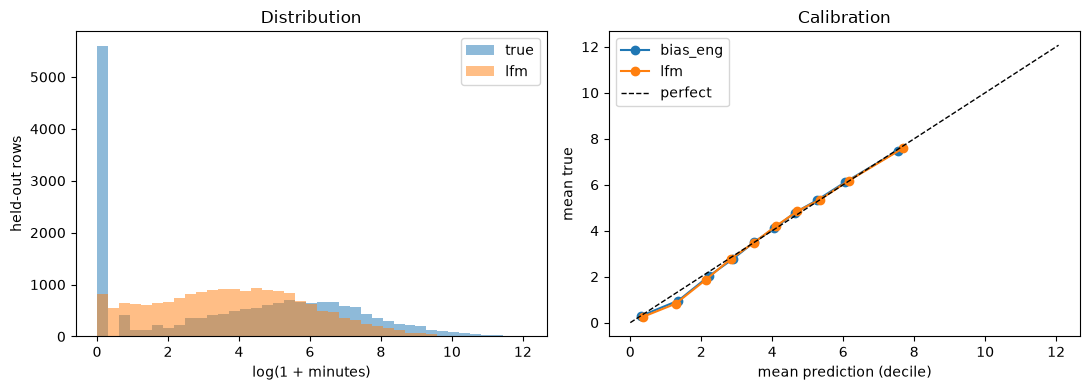

In [13]:
spread = pd.DataFrame({"true": y, **preds})
display(spread.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).T.round(2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
bins = np.linspace(0, y.max(), 40)
ax1.hist(y, bins=bins, alpha=0.5, label="true")
ax1.hist(preds["lfm"], bins=bins, alpha=0.5, label="lfm")
ax1.set(xlabel="log(1 + minutes)", ylabel="held-out rows", title="Distribution")
ax1.legend()

for name in ["bias_eng", "lfm"]:
    p = preds[name]
    decile = pd.qcut(p, 10, labels=False, duplicates="drop")
    cal = pd.DataFrame({"p": p, "y": y}).groupby(decile).mean()
    ax2.plot(cal.p, cal.y, "o-", label=name)
lim = [0, y.max()]
ax2.plot(lim, lim, "k--", lw=1, label="perfect")
ax2.set(xlabel="mean prediction (decile)", ylabel="mean true", title="Calibration")
ax2.legend()
plt.tight_layout()

**Takeaways (4.1–4.2):**
- In ratio terms the LFM is typically off by 4.0× (bias model 4.4×, global mean 28×); 27%
  of predictions are within 2× of the truth and 72% within 10×.
- Absolute error in minutes is misleading here: the global mean has the *lowest* median
  minutes error (30 vs 68), because a third of the truths are 0 and its 27-minute guess
  is close to 0 in minutes. Report ratios, not minutes.
- Predictions are narrower than the truth (std 2.17 vs 3.12; 10–90% range 0.8–6.7 vs
  0–7.8) but well calibrated: the model isn't predicting one typical value, it shrinks
  toward the middle at both ends and is right on average at every level.

### 4.3 Error by how much the game was actually played
`mean error` > 0 means over-predicting. `share of squared error` says which rows the MSE
comes from: a bucket whose share is much larger than its share of rows is where the
model struggles.

In [14]:
BUCKETS = [-np.inf, 0, 60, 600, 6000, np.inf]
LABELS = ["never (0)", "≤ 1 h", "1–10 h", "10–100 h", "100 h+"]


def by_bucket(y: np.ndarray, p: np.ndarray) -> pd.DataFrame:
    df = pd.DataFrame({"bucket": pd.cut(np.expm1(y), BUCKETS, labels=LABELS),
                       "err": p - y, "p": p})
    df["err2"] = df.err**2
    g = df.groupby("bucket", observed=True)
    return pd.DataFrame({
        "share of rows": g.size() / len(df),
        "median pred (min)": np.expm1(g.p.median()),
        "mean error (log)": g.err.mean(),
        "mse": g.err2.mean(),
        "share of squared error": g.err2.sum() / df.err2.sum(),
    }).round(3)


display(by_bucket(y, preds["lfm"]), by_bucket(y, preds["bias_eng"]))

,share of rows,median pred (min),mean error (log),mse,share of squared error
bucket,,,,,
never (0),0.310,3.959,1.941,6.158,0.407
≤ 1 h,0.194,23.738,0.633,3.014,0.125
1–10 h,0.260,90.756,-0.800,2.859,0.159
10–100 h,0.186,285.951,-1.699,5.232,0.208
100 h+,0.049,1260.686,-2.636,9.738,0.102


,share of rows,median pred (min),mean error (log),mse,share of squared error
bucket,,,,,
never (0),0.310,4.939,2.030,6.615,0.410
≤ 1 h,0.194,24.035,0.630,3.001,0.116
1–10 h,0.260,83.572,-0.867,2.978,0.155
10–100 h,0.186,247.454,-1.822,5.675,0.211
100 h+,0.049,992.782,-2.892,11.044,0.108


### 4.4 How much is the zeros?
An upper bound on what a perfect "never played" detector (the first stage of a hurdle
model) could gain: replace the prediction with 0 wherever the truth is 0, and keep the
rest. Also, how close does the model get to 0 when the truth is 0?

In [15]:
zero = y == 0
rows = {}
for name in ["bias_eng", "lfm"]:
    p = preds[name]
    rows[name] = {
        "mse (all rows)": np.mean((p - y) ** 2),
        "mse (played only)": np.mean((p[~zero] - y[~zero]) ** 2),
        "mse if zeros were perfect": np.mean((np.where(zero, 0, p) - y) ** 2),
        "median pred on never-played (min)": np.expm1(np.median(p[zero])),
        "lowest prediction (min)": np.expm1(p.min()),
    }
pd.DataFrame(rows).T.round(3)

,mse (all rows),mse (played only),mse if zeros were perfect,median pred on never-played (min),lowest prediction (min)
bias_eng,5.009,4.285,2.955,4.939,0.0
lfm,4.692,4.032,2.780,3.959,0.0


**Takeaways:**
- Never-played games are the largest source of error (41% of squared error from 31% of
  rows; mean error +1.9), but the median prediction for them is already ~4 minutes: the
  cost is a tail of zeros predicted much higher.
- Games played 10 h+ cost nearly as much (31% of squared error from 24% of rows; mean error
  −1.7 to −2.6): predictions shrink toward the middle at both ends, as squared error does
  when the model can't tell which end a game belongs to.
- The LFM beats `bias_eng` in every bucket, most at the extremes (never: 6.62 → 6.16;
  100 h+: 11.04 → 9.74).
- A perfect never-played detector would cut LFM MSE from 4.692 to 2.780 (−41%), ~6× the
  LFM's gain over `bias_eng`: the zeros are the biggest opportunity.
- Even on played games MSE is 4.03 (shrinkage at the top end, §4.3), which a second stage
  trained on played games only would target.
- Before clipping, some predictions were below 0 on the log scale (lowest: −0.87),
  impossible for log1p(minutes) → predictions are now clipped at 0 for the "minutes"
  target (lowest prediction above: 0 minutes).

In [16]:
import scipy.sparse as sp

from assignment_2.modules.core import calc_auc, interaction_matrix, item_similarity

tr = data.interactions
X, users, items = interaction_matrix(tr)        # owned, users × games
S = item_similarity(X, "jaccard")               # games by co-ownership; diagonal is 0
r, c = users.get_indexer(tr.user_id), items.get_indexer(tr.item_id)
played = sp.csr_matrix(((tr.playtime_forever > 0).to_numpy(float), (r, c)), shape=X.shape)
logmin = sp.csr_matrix((np.log1p(tr.playtime_forever.to_numpy(float)), (r, c)), shape=X.shape)

u, i = users.get_indexer(valid.user_id), items.get_indexer(valid.item_id)
assert (u >= 0).all() and (i >= 0).all(), "held-out users/games must be in train"


def knn_sum(M: sp.csr_matrix, chunk: int = 2000) -> np.ndarray:
    """For each held-out row: Σ_j sim(i, j) · M[u, j] over the user's train games."""
    out = np.empty(len(u))
    for s in range(0, len(u), chunk):  # chunks keep the sparse products small
        sl = slice(s, s + chunk)
        out[sl] = np.asarray(M[u[sl]].multiply(S[i[sl]]).sum(axis=1)).ravel()
    return out


w = knn_sum(X)                                   # total similarity to the user's games
has = w > 0
user_played = np.asarray(played.sum(axis=1)).ravel() / np.asarray(X.sum(axis=1)).ravel()
knn_played = np.where(has, knn_sum(played) / np.where(has, w, 1), user_played[u])
knn_reg = np.where(has, knn_sum(logmin) / np.where(has, w, 1), preds["bias_eng"])
print(f"held-out rows with a similar game in the user's library: {has.mean():.1%}")


def zero_rate(key: str, lam: float = 5.0) -> pd.Series:
    z = tr.playtime_forever == 0
    return (z.groupby(tr[key]).sum() + lam * z.mean()) / (tr.groupby(key).size() + lam)


signals = {  # higher = more likely never played
    "lfm prediction (negated)": -preds["lfm"],
    "user zero rate": valid.user_id.map(zero_rate("user_id")).to_numpy(),
    "item zero rate": valid.item_id.map(zero_rate("item_id")).to_numpy(),
    "kNN: share of similar games unplayed": 1 - knn_played,
    "kNN regressor (negated)": -knn_reg,
}
display(pd.Series({n: calc_auc(zero, s) for n, s in signals.items()},
                  name="AUC for never-played").round(3).to_frame())

preds["knn_reg"] = knn_reg
pd.DataFrame({n: {"mse": np.mean((preds[n] - y) ** 2), **in_minutes(y, preds[n])}
              for n in ["bias_eng", "lfm", "knn_reg"]}).T.round(3)

held-out rows with a similar game in the user's library: 100.0%


,AUC for never-played
lfm prediction (negated),0.865
user zero rate,0.674
item zero rate,0.829
kNN: share of similar games unplayed,0.699
kNN regressor (negated),0.691


,mse,median |error| (min),median ratio,within 2×,within 10×
bias_eng,5.009,69.250,4.422,0.259,0.697
lfm,4.692,67.877,4.040,0.265,0.722
knn_reg,8.652,93.529,8.917,0.160,0.524


**Takeaways:**
- The LFM's own prediction is the best ranker of never-played games (AUC 0.865); the item
  zero rate is next (0.829) but is already in the LFM through b_i. The user zero rate (0.674)
  and item kNN signals (~0.69–0.70) are weaker.
- So the zeros, though the largest source of error (§4.3–4.4), aren't predictable beyond
  what the LFM already knows: its hedge between "never played" and "played" is close to the
  best squared error allows. A hurdle model built on these signals is not pursued
  (future work: a classifier combining them on top of the LFM).
- Item kNN on co-ownership covers every row but isn't selective: popular games are co-owned
  with nearly everything. As a regressor it is far worse than the bias model (MSE 8.65,
  typically off by 8.9×), because it ignores how much the game itself is played → not
  registered.